# SDE Integration

Stochastic differential equations add noise to the dynamics:

$$dy = f(y, t)\,dt + g(y, t)\,dW_t,$$

where $W_t$ is a Wiener process with increments $\Delta W \sim \mathcal N(0, \Delta t)$. The SDE steppers in `braintools.quad` advance one step, like the ODE steppers, and take the drift `df(y, t, *args)` and the diffusion `dg(y, t, *args)` separately:

| Stepper | Interpretation | Strong order | Notes |
|---|---|---|---|
| `sde_euler_step` | Itô | 0.5 | Euler–Maruyama |
| `sde_milstein_step` | Itô or Stratonovich (`sde_type`) | 1.0 | derivative-free Milstein, diagonal noise |
| `sde_heun_step` | Itô or Stratonovich (`sde_type`) | Stratonovich 1.0, Itô 0.5 | predictor–corrector |
| `sde_srk2_step`, `sde_srk3_step`, `sde_srk4_step` | Stratonovich | 1.0 in general | Runge–Kutta tableaus on $f\,dt + g\,dW$ |
| `sde_expeuler_step` | Itô | 0.5 | drift integrated exponentially |
| `sde_tamed_euler_step` | Itô | 0.5 | drift tamed against superlinear growth |
| `sde_implicit_euler_step` | Itô | 0.5 | drift-implicit, solved with Newton's method |

This notebook covers:

1. the calling convention and random numbers;
2. Itô versus Stratonovich;
3. strong convergence with shared Brownian paths;
4. weak accuracy: the stationary variance of an Ornstein–Uhlenbeck process;
5. superlinear drifts: tamed and implicit Euler;
6. a population of noisy leaky integrate-and-fire neurons with units.

## 1. Setup and Calling Convention

In [1]:
from contextlib import contextmanager

import brainstate
import brainunit as u
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from scipy import integrate as sp_integrate

import braintools

jax.config.update("jax_enable_x64", True)

The steppers draw their Gaussian increments from `brainstate.random`, one draw per state leaf, with the shape of the state. Two consequences:

- **seed** with `brainstate.random.seed(...)` for reproducible runs;
- **use brainstate transformations** (`brainstate.transform.scan`, `brainstate.transform.jit`) around the steppers. A raw `jax.jit` or `jax.lax.scan` cannot track the random state and raises an error.

The helper below simulates many independent paths at once: the state is a vector with one entry per path.

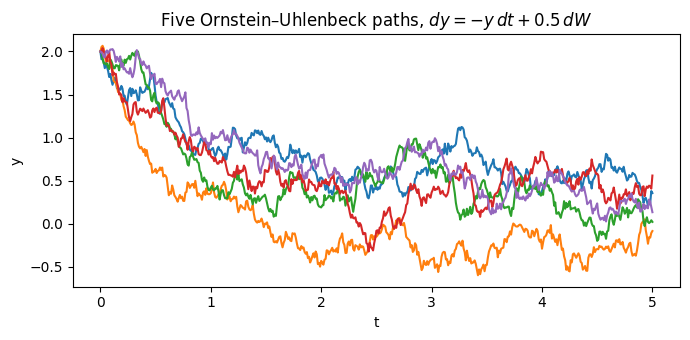

raw jax.jit -> TraceContextError


In [2]:
def simulate(step, df, dg, y0, dt, n_steps, *args, **kw):
    def body(y, i):
        y_next = step(df, dg, y, i * dt, *args, **kw)
        return y_next, y_next

    with brainstate.environ.context(dt=dt):
        _, ys = brainstate.transform.scan(body, y0, jnp.arange(n_steps))
    return jnp.concatenate([y0[None], ys])

brainstate.random.seed(0)
theta, sigma = 1.0, 0.5
ys = simulate(braintools.quad.sde_euler_step, lambda y, t: -theta * y, lambda y, t: sigma * jnp.ones_like(y),
              jnp.full(5, 2.0), 0.01, 500)
plt.figure(figsize=(7, 3.5))
plt.plot(np.arange(501) * 0.01, ys)
plt.xlabel("t"); plt.ylabel("y"); plt.title("Five Ornstein–Uhlenbeck paths, $dy = -y\\,dt + 0.5\\,dW$")
plt.tight_layout(); plt.show()

try:
    with brainstate.environ.context(dt=0.01):
        jax.jit(lambda y: braintools.quad.sde_euler_step(lambda y, t: -y, lambda y, t: 0.5, y, 0.0))(jnp.zeros(3))
except Exception as e:
    print("raw jax.jit ->", type(e).__name__)

## 2. Itô versus Stratonovich

When the diffusion depends on the state (multiplicative noise), the same formula $dy = f\,dt + g\,dW$ describes two different processes depending on where $g$ is evaluated within each increment: at its start (**Itô**) or at its midpoint (**Stratonovich**). The two are related by a drift correction:

$$\text{Stratonovich } (f, g) \;=\; \text{Itô } \left(f + \tfrac12 g\,\partial_y g,\; g\right).$$

Geometric Brownian motion $dy = \mu y\,dt + \sigma y\,dW$ makes the difference visible: under Itô, $\mathbb E[y_T] = y_0 e^{\mu T}$; under Stratonovich, $\mathbb E[y_T] = y_0 e^{(\mu + \sigma^2/2) T}$. Each stepper converges to the process of its own interpretation:

In [3]:
mu, sig = 0.5, 0.8
gbm_f = lambda y, t: mu * y
gbm_g = lambda y, t: sig * y
brainstate.random.seed(1)
y0 = jnp.ones(20000)
print(f"theory: Ito {np.exp(mu):.3f}   Stratonovich {np.exp(mu + sig ** 2 / 2):.3f}")
for name, kw in [("sde_euler_step", {}), ("sde_milstein_step", {"sde_type": "ito"}), ("sde_heun_step", {"sde_type": "ito"}),
                 ("sde_milstein_step", {"sde_type": "stra"}), ("sde_heun_step", {"sde_type": "stra"}), ("sde_srk2_step", {})]:
    yT = simulate(getattr(braintools.quad, name), gbm_f, gbm_g, y0, 0.01, 100, **kw)[-1]
    print(f"{name:20s} {str(kw):22s} E[y(1)] = {float(jnp.mean(yT)):.3f} ± {float(jnp.std(yT)) / np.sqrt(len(yT)):.3f}")

theory: Ito 1.649   Stratonovich 2.270


sde_euler_step       {}                     E[y(1)] = 1.653 ± 0.011
sde_milstein_step    {'sde_type': 'ito'}    E[y(1)] = 1.653 ± 0.011


sde_heun_step        {'sde_type': 'ito'}    E[y(1)] = 1.650 ± 0.011
sde_milstein_step    {'sde_type': 'stra'}   E[y(1)] = 2.244 ± 0.015


sde_heun_step        {'sde_type': 'stra'}   E[y(1)] = 2.267 ± 0.015
sde_srk2_step        {}                     E[y(1)] = 2.264 ± 0.015


Choose the interpretation from the model, not from the solver. Noise that is the limit of a fast but smooth physical process (for example colored synaptic noise with a vanishing correlation time) leads to Stratonovich; models defined as a limit of discrete-time updates, and most of the computational neuroscience literature, use Itô. With **additive noise** ($g$ independent of $y$) both interpretations coincide.

## 3. Strong Convergence

The **strong error** $\mathbb E\,|y_N - y(T)|$ compares a numerical path with the exact path **driven by the same Brownian motion**. To measure it, we need control over the random increments. The helper below temporarily replaces the noise source of the SDE module with prescribed standard normals, so that coarse runs can use sums of the increments of one fine Brownian path. It patches a private name and serves only for this experiment.

In [4]:
import braintools.quad._sde_integrator as sde_module

@contextmanager
def prescribed_normals(normals):
    # each call of the noise source returns the next row of `normals`
    rows = iter(normals)
    original = sde_module.randn_like
    sde_module.randn_like = lambda y: jnp.asarray(next(rows))
    try:
        yield
    finally:
        sde_module.randn_like = original

T, M, n_fine = 1.0, 2000, 2 ** 9
rng = np.random.default_rng(0)
dW_fine = rng.normal(size=(n_fine, M)) * np.sqrt(T / n_fine)   # one Brownian path per column
W_T = dW_fine.sum(0)

def coarse_run(step, df, dg, y0, k, **kw):
    # use the fine path aggregated over k fine steps per coarse step
    dt = T * k / n_fine
    normals = dW_fine.reshape(-1, k, M).sum(1) / np.sqrt(dt)
    y = jnp.full(M, y0)
    with prescribed_normals(normals), brainstate.environ.context(dt=dt):
        for j in range(n_fine // k):
            y = step(df, dg, y, j * dt, **kw)
    return np.asarray(y)

mu, sig = 1.5, 1.0
exact = {"ito": np.exp((mu - 0.5 * sig ** 2) * T + sig * W_T), "stra": np.exp(mu * T + sig * W_T)}
cases = [("sde_euler_step", {}, "ito"), ("sde_expeuler_step", {}, "ito"), ("sde_tamed_euler_step", {}, "ito"),
         ("sde_implicit_euler_step", {}, "ito"), ("sde_heun_step", {"sde_type": "ito"}, "ito"),
         ("sde_milstein_step", {"sde_type": "ito"}, "ito"), ("sde_milstein_step", {"sde_type": "stra"}, "stra"),
         ("sde_heun_step", {"sde_type": "stra"}, "stra"), ("sde_srk2_step", {}, "stra"),
         ("sde_srk3_step", {}, "stra"), ("sde_srk4_step", {}, "stra")]
ks = [32, 16, 8, 4]
dts = np.array(ks) * T / n_fine
strong = {}
for name, kw, kind in cases:
    e = np.array([np.mean(np.abs(coarse_run(getattr(braintools.quad, name), gbm_f, gbm_g, 1.0, k, **kw) - exact[kind]))
                  for k in ks])
    strong[(name, kw.get("sde_type", ""))] = e
    print(f"{name:24s} {kind:4s}  order {np.mean(np.log2(e[:-1] / e[1:])):.2f}   error at dt={dts[-1]:.4f}: {e[-1]:.1e}")

sde_euler_step           ito   order 0.51   error at dt=0.0078: 2.2e-01


sde_expeuler_step        ito   order 0.51   error at dt=0.0078: 2.2e-01
sde_tamed_euler_step     ito   order 0.60   error at dt=0.0078: 3.7e-01


sde_implicit_euler_step  ito   order 0.61   error at dt=0.0078: 2.2e-01
sde_heun_step            ito   order 0.50   error at dt=0.0078: 2.2e-01


sde_milstein_step        ito   order 1.00   error at dt=0.0078: 6.4e-02
sde_milstein_step        stra  order 0.94   error at dt=0.0078: 1.4e-01
sde_heun_step            stra  order 0.95   error at dt=0.0078: 5.6e-02
sde_srk2_step            stra  order 0.95   error at dt=0.0078: 5.6e-02


sde_srk3_step            stra  order 1.07   error at dt=0.0078: 7.7e-03
sde_srk4_step            stra  order 1.90   error at dt=0.0078: 1.2e-04


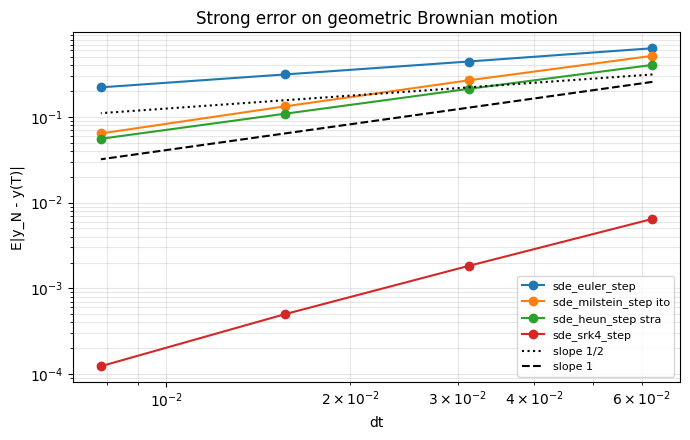

In [5]:
plt.figure(figsize=(7, 4.5))
for key in [("sde_euler_step", ""), ("sde_milstein_step", "ito"), ("sde_heun_step", "stra"), ("sde_srk4_step", "")]:
    plt.loglog(dts, strong[key], "o-", label=" ".join(k for k in key if k))
plt.loglog(dts, 0.5 * strong[("sde_euler_step", "")][-1] * (dts / dts[-1]) ** 0.5, "k:", label="slope 1/2")
plt.loglog(dts, 0.5 * strong[("sde_milstein_step", "ito")][-1] * (dts / dts[-1]), "k--", label="slope 1")
plt.xlabel("dt"); plt.ylabel("E|y_N - y(T)|"); plt.title("Strong error on geometric Brownian motion")
plt.legend(fontsize=8); plt.grid(True, which="both", alpha=0.3); plt.tight_layout(); plt.show()

The Euler family converges with order 1/2, Milstein (both interpretations) and the Stratonovich Heun/SRK2 schemes with order 1, as expected. Tamed Euler has a larger error constant because taming changes the drift $\mu y$ wherever $\Delta t\,|f|$ is not small.

`sde_srk3_step` and `sde_srk4_step` look much better on GBM: an error 7 times smaller than SRK2 for SRK3, and order 2 for SRK4. This is a special property of GBM: its drift and diffusion are proportional, so in Stratonovich form the solution depends only on $s = \mu t + \sigma W_t$, and the scheme behaves like the deterministic Runge–Kutta method in $s$. On a general equation the advantage disappears:

In [6]:
# Stratonovich SDE whose drift and diffusion are not proportional: dy = -y dt + 0.5 cos(y) o dW
f2 = lambda y, t: -y
g2 = lambda y, t: 0.5 * jnp.cos(y)
reference = coarse_run(braintools.quad.sde_srk4_step, f2, g2, 1.0, 1)   # finest grid as reference
for name, kw in [("sde_heun_step", {"sde_type": "stra"}), ("sde_srk2_step", {}), ("sde_srk4_step", {})]:
    e = np.array([np.mean(np.abs(coarse_run(getattr(braintools.quad, name), f2, g2, 1.0, k, **kw) - reference))
                  for k in [64, 32, 16, 8]])
    print(f"{name:16s} order {np.round(np.log2(e[:-1] / e[1:]), 2)}   errors {['%.1e' % x for x in e]}")

sde_heun_step    order [0.94 0.99 1.07]   errors ['1.1e-02', '5.7e-03', '2.9e-03', '1.4e-03']
sde_srk2_step    order [0.94 0.99 1.07]   errors ['1.1e-02', '5.7e-03', '2.9e-03', '1.4e-03']
sde_srk4_step    order [0.93 1.   1.07]   errors ['1.1e-02', '5.6e-03', '2.8e-03', '1.3e-03']


On a general equation all Stratonovich Runge–Kutta schemes have strong order 1 and nearly identical errors: a scheme that sees the noise only through the increments $\Delta W$ cannot exceed order 1 (Clark–Cameron). The extra stages of `sde_srk3_step` and `sde_srk4_step` improve the drift part, which matters only when the drift dominates the error.

## 4. Weak Accuracy: Stationary Variance

Often only statistics matter: firing rates, variances, distributions. For the Ornstein–Uhlenbeck process $dy = -\theta y\,dt + \sigma\,dW$ the stationary variance is $\sigma^2 / (2\theta)$. Each scheme has its own stationary variance, which depends on $\theta\,\Delta t$:

| Scheme | Stationary variance |
|---|---|
| Euler–Maruyama | $\sigma^2 / \big(\theta\,(2 - \theta\Delta t)\big)$, unstable for $\theta \Delta t \ge 2$ |
| exponential Euler | $\sigma^2 \Delta t / (1 - e^{-2\theta\Delta t})$ |
| drift-implicit Euler | $\sigma^2 / \big(\theta\,(2 + \theta\Delta t)\big)$ |

In [7]:
theta, sigma = 1.0, 1.0
f_ou = lambda y, t: -theta * y
g_ou = lambda y, t: sigma * jnp.ones_like(y)
theory = {"sde_euler_step": lambda h: sigma ** 2 / (theta * (2 - theta * h)),
          "sde_expeuler_step": lambda h: sigma ** 2 * h / (1 - np.exp(-2 * theta * h)),
          "sde_implicit_euler_step": lambda h: sigma ** 2 / (theta * (2 + theta * h))}
brainstate.random.seed(2)
for h in [0.01, 0.1, 0.5, 1.0]:
    line = f"theta*dt = {theta * h:<5}"
    for name in theory:
        yT = simulate(getattr(braintools.quad, name), f_ou, g_ou, jnp.zeros(20000), h, int(20 / h))[-1]
        line += f"   {name.replace('sde_', '').replace('_step', '')}: {float(jnp.var(yT)):.3f} (theory {theory[name](h):.3f})"
    print(line, f"   exact {sigma ** 2 / (2 * theta):.3f}")

theta*dt = 0.01    euler: 0.504 (theory 0.503)   expeuler: 0.502 (theory 0.505)   implicit_euler: 0.499 (theory 0.498)    exact 0.500


theta*dt = 0.1     euler: 0.519 (theory 0.526)   expeuler: 0.556 (theory 0.552)   implicit_euler: 0.479 (theory 0.476)    exact 0.500


theta*dt = 0.5     euler: 0.661 (theory 0.667)   expeuler: 0.808 (theory 0.791)   implicit_euler: 0.401 (theory 0.400)    exact 0.500


theta*dt = 1.0     euler: 0.998 (theory 1.000)   expeuler: 1.145 (theory 1.157)   implicit_euler: 0.334 (theory 0.333)    exact 0.500


All three schemes agree with their predicted stationary variance; at $\theta\Delta t = 1$ Euler–Maruyama and exponential Euler overestimate the true value 0.5 by a factor of 2 and 2.3, drift-implicit Euler underestimates it by a third. Integrating the drift exactly (exponential Euler) does **not** make the noise statistics exact, because the noise is still added in Euler form. For linear SDEs with additive noise an exact update exists: $y_{n+1} = e^{-\theta \Delta t} y_n + \sigma\sqrt{(1 - e^{-2\theta\Delta t})/(2\theta)}\,\xi_n$; `braintools.input.ou_process` generates OU input currents this way.

## 5. Superlinear Drifts: Tamed and Implicit Euler

For drifts that grow faster than linearly, such as the double-well $f(y) = y - y^3$, Euler–Maruyama can diverge: a rare large noise kick sends $y$ to a region where $\Delta t\,|f(y)|$ overshoots further, and the path explodes. `sde_tamed_euler_step` divides the drift increment by $1 + \Delta t\,|f|$; `sde_implicit_euler_step` evaluates the drift at the end of the step and solves the resulting equation with Newton's method. We run 10 000 paths of $dy = (y - y^3)\,dt + 2\,dW$ for 20 time units and compare $\mathbb E[y^2]$ with the exact stationary value.

In [8]:
f_dw = lambda y, t: y - y ** 3
g_dw = lambda y, t: 2.0 * jnp.ones_like(y)
# stationary density ~ exp(2 U(y) / sigma^2) with U(y) = y^2/2 - y^4/4
w = lambda y: np.exp((y ** 2 / 2 - y ** 4 / 4) * 2 / 2.0 ** 2)
Ey2 = sp_integrate.quad(lambda y: y ** 2 * w(y), -10, 10)[0] / sp_integrate.quad(w, -10, 10)[0]
print(f"exact stationary E[y^2] = {Ey2:.3f}")

brainstate.random.seed(3)
for h in [0.05, 0.2, 0.4, 0.8]:
    line = f"dt = {h:<5}"
    for name in ["sde_euler_step", "sde_tamed_euler_step", "sde_implicit_euler_step"]:
        yT = np.asarray(simulate(getattr(braintools.quad, name), f_dw, g_dw, jnp.zeros(10000), h, int(20 / h))[-1])
        bad = ~np.isfinite(yT) | (np.abs(yT) > 1e3)
        stat = f"E[y^2] = {np.mean(yT ** 2):.2f}" if not bad.any() else "E[y^2] =   --"
        line += f"   {name.replace('sde_', '').replace('_step', ''):14s} {100 * bad.mean():5.1f}% diverged, {stat}"
    print(line)

exact stationary E[y^2] = 1.290


dt = 0.05    euler            0.0% diverged, E[y^2] = 1.28   tamed_euler      0.0% diverged, E[y^2] = 1.43   implicit_euler   0.0% diverged, E[y^2] = 1.31


dt = 0.2     euler           28.8% diverged, E[y^2] =   --   tamed_euler      0.0% diverged, E[y^2] = 2.11   implicit_euler   0.0% diverged, E[y^2] = 1.34


dt = 0.4     euler           98.8% diverged, E[y^2] =   --   tamed_euler      0.0% diverged, E[y^2] = 3.63   implicit_euler   0.0% diverged, E[y^2] = 1.46


dt = 0.8     euler          100.0% diverged, E[y^2] =   --   tamed_euler      0.0% diverged, E[y^2] = 8.42   implicit_euler   0.0% diverged, E[y^2] = 1.77


- Euler–Maruyama is fine at `dt = 0.05`, diverges on 29 % of the paths at `dt = 0.2` and on almost all paths beyond.
- Tamed Euler never diverges, but its statistics are biased, already at `dt = 0.05` and strongly at large steps ($\mathbb E[y^2] = 8.4$ instead of 1.29 at `dt = 0.8`): taming bounds the drift increment, so the restoring force $-y^3$ is too weak far from the wells.
- Drift-implicit Euler stays stable and closest to the exact statistics; its Newton solve costs a few drift evaluations and Jacobian-vector products per step.

Prefer tamed Euler when the step is already small and you only need protection against rare explosions; prefer implicit Euler when you want large steps.

## 6. Example: Noisy Leaky Integrate-and-Fire Neurons

A population of uncoupled LIF neurons with membrane noise,

$$dV = \frac{V_{rest} - V + \mu}{\tau}\,dt + \sigma\sqrt{\frac{2}{\tau}}\,dW, \qquad V \ge V_{th} \Rightarrow V \leftarrow V_{reset},$$

where $\sigma$ is the standard deviation of the free membrane potential. With units, the diffusion must have **state units per square-root time** (here mV/√ms); a mismatch raises an error. The mean input $\mu$ keeps the mean potential below threshold, so spikes are noise-driven.

mean rate 22.51 Hz


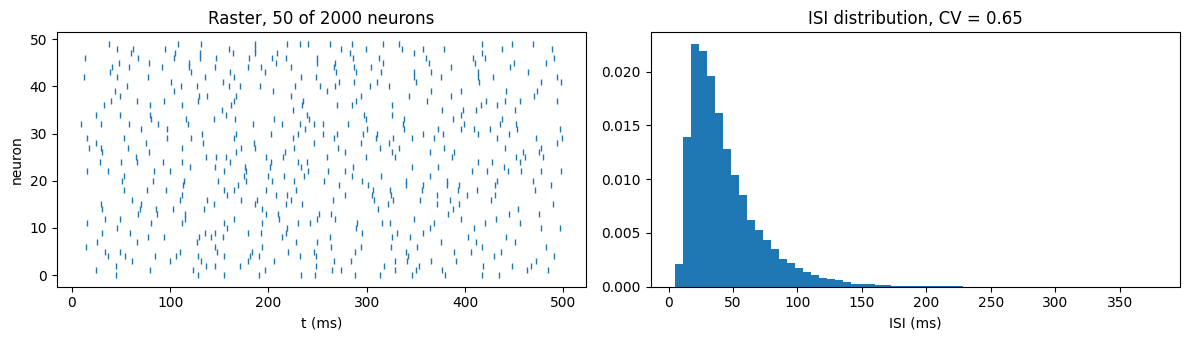

In [9]:
tau, V_rest, V_th, V_reset = 10.0 * u.ms, -65.0 * u.mV, -50.0 * u.mV, -65.0 * u.mV
mu_in, sigma_V = 12.0 * u.mV, 3.0 * u.mV

def drift(V, t):
    return (V_rest - V + mu_in) / tau

def diffusion(V, t):
    return sigma_V * u.math.sqrt(2.0 / tau) * u.math.ones_like(u.get_mantissa(V))

def run_lif(step, dt, n_neurons=2000, duration=2000.0 * u.ms):
    n = int(duration / dt)

    def body(V, i):
        V = step(drift, diffusion, V, i * dt)
        spike = V >= V_th
        return u.math.where(spike, V_reset, V), spike

    with brainstate.environ.context(dt=dt):
        V0 = V_rest + u.math.zeros(n_neurons) * u.mV
        _, spikes = brainstate.transform.scan(body, V0, jnp.arange(n))
    return np.asarray(spikes)

brainstate.random.seed(4)
spikes = run_lif(braintools.quad.sde_expeuler_step, 0.1 * u.ms)
rates = spikes.sum(0) / 2.0
print(f"mean rate {rates.mean():.2f} Hz")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
t_idx, n_idx = np.nonzero(spikes[:5000, :50])
ax[0].plot(t_idx * 0.1, n_idx, "|", ms=4)
ax[0].set_xlabel("t (ms)"); ax[0].set_ylabel("neuron"); ax[0].set_title("Raster, 50 of 2000 neurons")
isi = np.concatenate([np.diff(np.nonzero(spikes[:, i])[0]) * 0.1 for i in range(spikes.shape[1])])
ax[1].hist(isi, bins=60, density=True)
ax[1].set_xlabel("ISI (ms)"); ax[1].set_title(f"ISI distribution, CV = {isi.std() / isi.mean():.2f}")
plt.tight_layout(); plt.show()

The step size matters more for spiking than for the subthreshold dynamics. Between two grid points a path can cross the threshold and come back unnoticed, so coarse steps **underestimate** the firing rate of noise-driven neurons:

In [10]:
brainstate.random.seed(5)
for dt in [0.5, 0.2, 0.1, 0.05, 0.02]:
    line = f"dt = {dt:<5} ms"
    for name in ["sde_euler_step", "sde_expeuler_step"]:
        r = run_lif(getattr(braintools.quad, name), dt * u.ms).sum(0).mean() / 2.0
        line += f"   {name}: {r:6.2f} Hz"
    print(line)

dt = 0.5   ms   sde_euler_step:  21.10 Hz   sde_expeuler_step:  20.95 Hz


dt = 0.2   ms   sde_euler_step:  21.94 Hz   sde_expeuler_step:  21.86 Hz


dt = 0.1   ms   sde_euler_step:  22.45 Hz   sde_expeuler_step:  22.45 Hz


dt = 0.05  ms   sde_euler_step:  22.85 Hz   sde_expeuler_step:  22.82 Hz


dt = 0.02  ms   sde_euler_step:  23.21 Hz   sde_expeuler_step:  23.23 Hz


The rate increases by 10 % between `dt = 0.5 ms` and `dt = 0.02 ms` and is still changing. The missed crossings make the error decay only like $\sqrt{\Delta t}$: a fit $r(\Delta t) = r_0 - c\sqrt{\Delta t}$ to these numbers gives $r_0 \approx 23.7$ Hz, so even `dt = 0.1 ms` underestimates the rate by about 5 %. Euler and exponential Euler agree here because $\Delta t \ll \tau$; the integration scheme is not the bottleneck, the threshold detection is.

## Summary

- SDE steppers take `df` and `dg` separately, read `dt` from `brainstate.environ`, and draw noise from `brainstate.random`: seed it, and wrap loops in `brainstate.transform.scan` or `brainstate.transform.jit`, not raw JAX transformations.
- With multiplicative noise, Itô and Stratonovich describe different processes. `sde_euler_step`, `sde_expeuler_step`, `sde_tamed_euler_step` and `sde_implicit_euler_step` are Itô; the SRK steppers are Stratonovich; `sde_milstein_step` and `sde_heun_step` take `sde_type`.
- Strong orders: 0.5 for the Euler family, 1 for Milstein and the Stratonovich Heun/SRK schemes. Higher orders appear only in special cases such as GBM.
- Weak statistics depend on $\Delta t$ in a scheme-specific way; check them against a smaller step. Exponential Euler does not make noise statistics exact.
- For superlinear drifts, use `sde_tamed_euler_step` (always explicit, cheap) or `sde_implicit_euler_step` (Newton solve, more accurate statistics at large steps).
- For spiking models, the step size controls the detection of threshold crossings; check rates against a smaller step.